# Признак режима спроса для RL-агента управления запасами

Итоговый проект по курсу «Обучение с подкреплением» (МИФИ / SkillFactory), трек 2: собственная среда.

Склад одного товара, спрос переключается между спокойным режимом и шоком. Сравниваются два агента PPO,
которые отличаются только одним признаком в наблюдении — вероятностью шока, посчитанной по последним
значениям спроса. Ноутбук не обучает модели, а читает результаты `train.py`, `tune_baselines.py` и
`evaluate.py` (команды — в разделе 10 и в README) и строит по ним графики и таблицы.

## 1. Вопрос и гипотеза

**Вопрос.** Помогает ли агенту PPO явный признак режима — вероятность шока, посчитанная фильтром
Гамильтона по последним 4 значениям спроса, — если эти же 4 значения уже есть в его наблюдении? Меняет ли
признак то, как агент держит страховой запас в шоковые периоды, и снижает ли он стоимость и дефицит?

Признак — детерминированная функция наблюдения, новой информации он не добавляет. Поэтому сравнение
проверяет не «больше данных — лучше», а то, может ли агент за ограниченный бюджет сам выделить режим из
сырого спроса. Для меня вопрос связан с темой ВКР (прогнозирование с учётом режимов): имеет ли смысл
передавать в модель принятия решений готовую оценку режима, а не только сырые данные.

**Гипотеза H1** (зафиксирована до основного обучения, первый коммит репозитория). При одинаковом бюджете
(500k шагов) агент с признаком режима по сравнению с базовым:

1. различает режимы: разница среднего целевого уровня S в шоковые и спокойные шаги у него больше;
2. реже допускает дефицит в шоковые шаги;
3. имеет меньшую среднюю стоимость эпизода на тестовом сценарии с тем же распределением, что при обучении:
   ожидалось снижение на 3–8 %, разница значима по критерию Уэлча по 5 seed (p < 0,05);
4. сохраняет преимущество при частых и длинных шоках; при более сильных шоках (σ = 9) преимущество может
   пропасть, потому что фильтр считает с неверными параметрами.

**Обоснование.** Лучший постоянный уровень S — компромисс: он завышен для спокойного режима и занижен для
шока. В пилоте (100 отдельных эпизодов) правило «два уровня S с переключением по признаку» было дешевле
лучшего постоянного уровня на 8,6 %, оракул с истинным режимом — на 18 %. Тот же фильтр по всей истории
спроса давал почти то же, что по 4 последним значениям (8,6 % против 8,4 %), то есть базовому агенту
хватает информации. Но признак — нелинейная функция спроса (сравнение квадратов отклонений от средних двух
режимов), а сигнал награды шумный: дефицит из-за заниженного уровня проявляется через 2–3 шага и смешан со
случайностью спроса. В пилотных запусках для подбора гиперпараметров базовый агент сходился к почти
постоянному уровню.

**Решающее правило.** H1 подтверждена, если выполнены пункты 1–3; частично — если направление эффектов
верное, но p ≥ 0,05; опровергнута — если агент с признаком не дешевле базового.

**Дополнительный вопрос** (эффективность обучения): при бюджете 1,5M шагов (3 seed на условие) разрыв
должен сократиться, но не исчезнуть.

До фиксации гипотезы был один пробный запуск агента с признаком (1 seed, 400k шагов) — проверка, что
обучение вообще работает; в результаты он не входит.

In [1]:
import json
import os
import re
from pathlib import Path

os.environ.setdefault("OMP_NUM_THREADS", "1")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from scipy import stats
from stable_baselines3 import PPO

from inventory_rl import config
from inventory_rl.env import SHOCK, InventoryRegimeEnv
from inventory_rl.evaluation import rollout, summarize
from inventory_rl.policies import BaseStockPolicy, OracleBaseStockPolicy, SB3Policy, SignalBaseStockPolicy

torch.set_num_threads(1)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

POLICY_LABELS = {
    "random": "Случайная",
    "base_stock_calm": "Base-stock, уровень для спокойного режима",
    "base_stock_static": "Base-stock, лучший постоянный уровень",
    "base_stock_signal": "Два уровня по признаку режима",
    "oracle": "Два уровня по истинному режиму (оракул)",
    "base": "PPO без признака",
    "regime": "PPO с признаком",
    "base_long": "PPO без признака, 1.5M шагов",
    "regime_long": "PPO с признаком, 1.5M шагов",
}
SCENARIO_LABELS = {
    "base": "Как при обучении",
    "empty_in_shock": "Пустой склад, шок",
    "overstock": "Затоваривание",
    "frequent_shocks": "Частые шоки",
    "long_shocks": "Длинные шоки",
    "strong_shocks": "Сильные шоки",
}
COLORS = {"base": "tab:blue", "regime": "tab:orange", "base_stock_static": "tab:gray",
          "base_stock_signal": "tab:green", "oracle": "tab:purple"}

baselines = json.loads(Path("results/baselines.json").read_text())
HEURISTICS = {
    "base_stock_static": BaseStockPolicy(*baselines["base_stock_static"]),
    "base_stock_signal": SignalBaseStockPolicy(*baselines["base_stock_signal"]),
    "oracle": OracleBaseStockPolicy(*baselines["oracle"]),
}


def shock_signal(env):
    # Спрос сгенерирован при reset и от действий не зависит, поэтому признак по шагам эпизода
    # можно посчитать без прогона политики.
    values = []
    for t in range(env.horizon):
        env.t = t
        values.append(env.shock_probability())
    env.t = 0
    return np.array(values)


def shade_shocks(ax, regime, t0=0):
    # Закрашивает шаги шокового режима.
    for t in np.flatnonzero(regime == SHOCK):
        ax.axvspan(t0 + t - 0.5, t0 + t + 0.5, color="tab:red", alpha=0.12, lw=0)

## 2. Среда `InventoryRegimeEnv`

Код — `inventory_rl/env.py`, интерфейс Gymnasium (проверен `gymnasium.utils.env_checker.check_env`).

**Спрос.** Скрытый режим — марковская цепь: P(спокойный → шок) = 0,04, P(шок → спокойный) = 0,10, т. е.
средняя длина спокойного периода 25 шагов, шока — 10, доля шоковых шагов 29 %. Спрос
D = max(0, round(N(μ, σ²))): в спокойном режиме μ = 10, σ = 2, в шоке μ = 13, σ = 6. Шок — это прежде
всего рост неопределённости (σ втрое), среднее растёт на 30 %.

**Порядок событий на шаге.** (1) Агент выбирает целевой уровень S; заказ q = max(0, S − IP), где IP —
позиция запаса (склад + заказы в пути). (2) Приходит заказ, сделанный 2 шага назад (срок поставки L = 2).
(3) Реализуется спрос, неудовлетворённая часть теряется. (4) Начисляется стоимость.

**Состояние и наблюдение.** Полное состояние — запас на складе, 2 заказа в пути, история спроса и скрытый
режим. Агент видит (базовое условие, 7 чисел): запас на складе / 50, два заказа в пути / 50, 4 последних
значения спроса / 20. Режим ему не виден.

**Признак режима** (экспериментальное условие, +1 число) — вероятность шока на текущем шаге по тем же 4
значениям спроса. Фильтр Гамильтона с параметрами обучающего процесса, начиная со стационарной вероятности
π = 0,29, для каждого значения d: обновление π ← π·f_шок(d) / (π·f_шок(d) + (1 − π)·f_спок(d)), где f —
плотность нормального распределения режима; затем прогноз на шаг π ← 0,9·π + 0,04·(1 − π).

**Действие** — S ∈ {0, …, 80}, `Discrete(81)`. Это та же политика заказа, что и «объём заказа»
(q = S − IP при S ≥ IP), но хорошее действие почти не зависит от состояния, и PPO учится быстрее: в пилоте с
действием «объём заказа» PPO за 200k шагов не догонял постоянный base-stock. Политика base-stock в этой
параметризации — постоянное действие.

**Награда** r = −(h·I + p·lost + c·q), где I — запас на складе в конце шага, lost — потерянный спрос,
q — заказ; h = 1, p = 20, c = 1. Сумма наград за эпизод — это минус полная стоимость эпизода, т. е. ровно
та метрика, по которой сравниваются политики. Составляющие задают настоящий компромисс склада: высокий
уровень — плата за хранение, низкий — потерянные продажи (маржа и лояльность клиента), закупка не даёт
заказывать впрок бесплатно. Отношение p/(p + h) ≈ 0,95 соответствует товару с высокой маржой, где дефицит
дорог. При обучении награда делится на 20 (масштаб для value-функции), оптимальная политика от этого не
меняется.

**Конец эпизода** — через 100 шагов, только по времени (`truncated`), терминальных состояний нет.

**Начальное состояние при обучении:** запас ~ U{20..60}, заказов в пути нет, режим из стационарного
распределения, 4 значения предыстории спроса генерируются тем же процессом.

**Общие случайные числа.** Путь режимов и спроса генерируется при `reset` из seed и не зависит от действий,
поэтому все политики оцениваются на одних и тех же реализациях спроса.

Пример эпизода и признака режима:

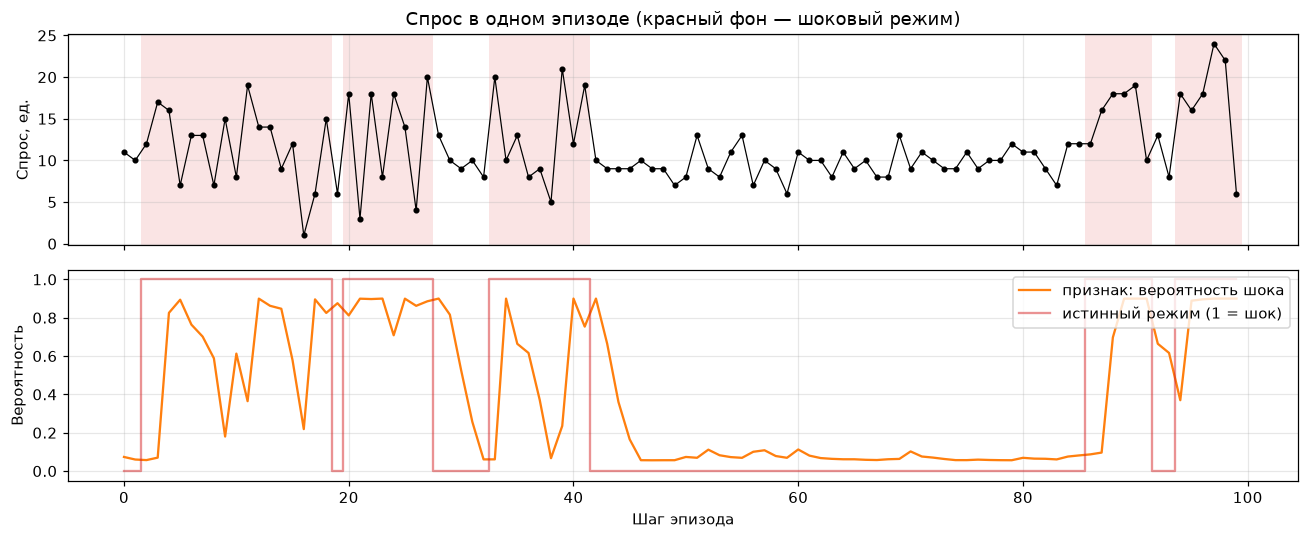

Средний признак в шоковые шаги: 0.63, в спокойные: 0.16
Признак > 0.5: в 70% шоковых шагов и в 8% спокойных


In [2]:
env = InventoryRegimeEnv()
env.reset(seed=7)  # произвольный seed только для иллюстрации
demand, regime = env.demands[env.history_len:], env.regimes[env.history_len:]
signal = shock_signal(env)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
ax1.plot(demand, "k.-", lw=0.8)
shade_shocks(ax1, regime)
ax1.set(ylabel="Спрос, ед.", title="Спрос в одном эпизоде (красный фон — шоковый режим)")
ax2.plot(signal, color="tab:orange", label="признак: вероятность шока")
ax2.step(np.arange(env.horizon), regime, where="mid", color="tab:red", alpha=0.5, label="истинный режим (1 = шок)")
ax2.set(xlabel="Шаг эпизода", ylabel="Вероятность", ylim=(-0.05, 1.05))
ax2.legend(loc="upper right")
plt.tight_layout()
plt.show()

# Качество признака на тестовых эпизодах: насколько он отделяет шоковые шаги от спокойных
signals, regimes = [], []
for seed in config.TEST_SEEDS:
    env.reset(seed=seed)
    signals.append(shock_signal(env))
    regimes.append(env.regimes[env.history_len:])
signals, regimes = np.concatenate(signals), np.concatenate(regimes)
print(f"Средний признак в шоковые шаги: {signals[regimes == SHOCK].mean():.2f}, "
      f"в спокойные: {signals[regimes != SHOCK].mean():.2f}")
print(f"Признак > 0.5: в {np.mean(signals[regimes == SHOCK] > 0.5):.0%} шоковых шагов "
      f"и в {np.mean(signals[regimes != SHOCK] > 0.5):.0%} спокойных")

## 3. Условия, алгоритм, эталоны и протокол оценки

**Условия.** `base` — наблюдение из 7 чисел; `regime` — те же 7 чисел плюс вероятность шока. Среда,
награда, алгоритм, гиперпараметры, бюджет, seed обучения и процедура оценки одинаковые.

**Алгоритм** — PPO из Stable-Baselines3, `MlpPolicy` (два слоя по 64), 8 параллельных сред. Почти все
гиперпараметры — значения по умолчанию SB3; γ = 0,95 и коэффициент энтропии 0,01 выбраны в пилоте по
базовому условию (5 сочетаний γ ∈ {0,95; 0,99} и коэффициента энтропии ∈ {0; 0,01; 0,03}, 1–2 seed,
400–500k шагов), чтобы не подыгрывать гипотезе. γ = 0,95 даёт
горизонт около 20 шагов — больше срока поставки и средней длины шока.

**Бюджет.** Основной эксперимент: 500k шагов, 5 seed на условие (0–4). Проверка эффективности обучения:
1,5M шагов, 3 seed на условие (0–2). Выбора модели по валидации нет: оценивается модель после последнего
шага обучения.

**Эталоны** (уровни подобраны перебором по сетке на 300 эпизодах, seed 60000–60299):
- случайная политика: S ~ U{0..80} на каждом шаге;
- base-stock с уровнем для спокойного режима: постоянный S, подобранный на спросе без шоков — так настроил
  бы склад планировщик по спокойной истории;
- base-stock с лучшим постоянным уровнем на обучающем распределении;
- два уровня S с переключением по порогу на тот же признак, что у агента, — эвристический аналог
  экспериментального условия;
- два уровня S по истинному режиму (оракул) — верхний ориентир, агентам режим недоступен.

**Оценка.** Жадная (детерминированная) политика, 200 тестовых эпизодов на сценарий (seed 100000–100199,
не используются ни в обучении, ни в подборе), одни и те же эпизоды для всех политик. Для PPO метрика
сначала усредняется по 200 эпизодам для каждого seed, затем приводится среднее ± стандартное отклонение
по seed. Кривые обучения — на отдельных 50 валидационных эпизодах (seed 50000–50049) каждые 20k шагов.

**Метрики:** средняя стоимость эпизода (основная); доля шагов с дефицитом — всего, в шоковые и в спокойные
шаги; доля потерянного спроса; средний уровень и средний запас на складе по режимам; составляющие стоимости.
Уровень измеряется как позиция запаса после заказа, max(S, позиция до заказа): любое S ниже текущей
позиции даёт тот же нулевой заказ, поэтому само действие в таких состояниях ничего не говорит о политике
(агент может выбрать и S = 0). Для base-stock это просто S, пока позиция не выше S.

In [3]:
print("Гиперпараметры PPO:", config.PPO_PARAMS, "| n_envs =", config.N_ENVS)
print("Подобранные эвристики:", baselines)

scenario_rows = []
for sc in config.TEST_SCENARIOS:
    r = sc.regimes
    scenario_rows.append({
        "сценарий": SCENARIO_LABELS[sc.name],
        "P(спок→шок)": r.p_calm_to_shock, "P(шок→спок)": r.p_shock_to_calm,
        "σ шока": r.shock_std, "доля шока": round(r.stationary_shock_share(), 2),
        "начальный запас": f"{sc.init_inventory[0]}–{sc.init_inventory[1]}",
        "начальный режим": {None: "стационарный", 0: "спокойный", 1: "шок"}[sc.start_regime],
    })
pd.DataFrame(scenario_rows).set_index("сценарий")

Гиперпараметры PPO: {'n_steps': 256, 'batch_size': 256, 'n_epochs': 10, 'learning_rate': 0.0003, 'gamma': 0.95, 'gae_lambda': 0.95, 'ent_coef': 0.01, 'policy_kwargs': {'net_arch': [64, 64]}} | n_envs = 8
Подобранные эвристики: {'base_stock_calm': [35], 'base_stock_static': [41], 'oracle': [36, 51], 'base_stock_signal': [37, 50, 0.35]}


,P(спок→шок),P(шок→спок),σ шока,доля шока,начальный запас,начальный режим
сценарий,,,,,,
Как при обучении,0.04,0.10,6.0,0.29,20–60,стационарный
"Пустой склад, шок",0.04,0.10,6.0,0.29,0–0,шок
Затоваривание,0.04,0.10,6.0,0.29,100–100,спокойный
Частые шоки,0.12,0.10,6.0,0.55,20–60,стационарный
Длинные шоки,0.04,0.05,6.0,0.44,20–60,стационарный
Сильные шоки,0.04,0.10,9.0,0.29,20–60,стационарный


Первый сценарий — то же распределение, что при обучении, на новых seed. Два следующих меняют начальное
состояние: пустой склад в начале шока (такого запаса при обучении не было) и затоваривание 100 единиц.
Последние три меняют динамику спроса, которой агент не видел: шоки втрое чаще, вдвое длиннее или с σ = 9.
Фильтр во всех сценариях считает с обучающими параметрами, как было бы на практике после смены режима
рынка.

## 4. Кривые обучения

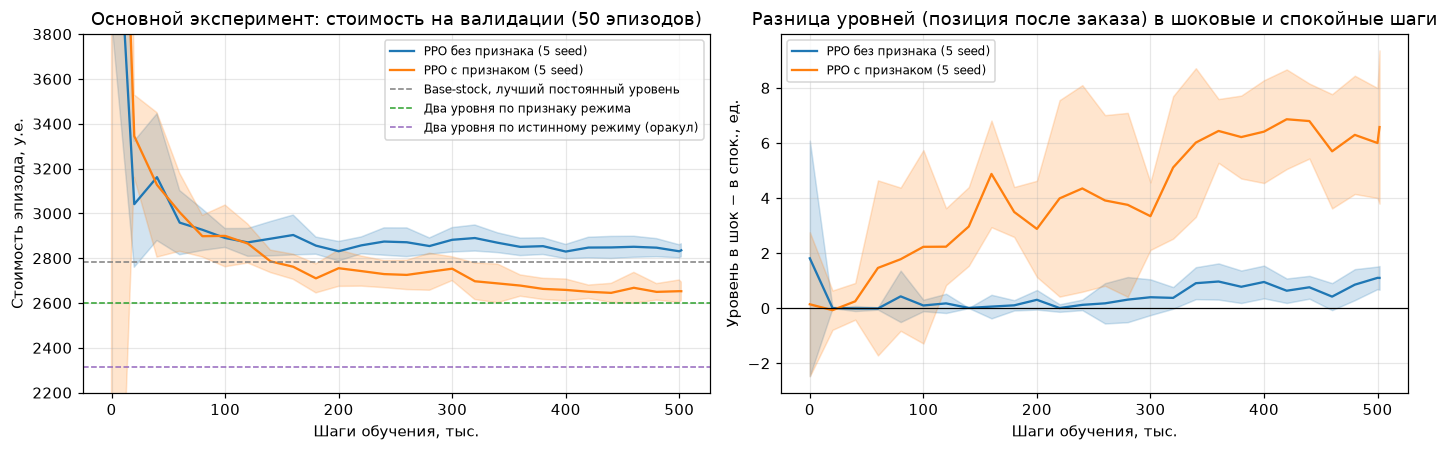

Линия — среднее по seed, заливка — ± стандартное отклонение по seed; пунктир — эвристики на тех же эпизодах.
Стоимость необученной политики (шаг 0), среднее по seed: {'base': 4840.0, 'regime': 6210.0}
Эвристики на валидационных эпизодах: {'base_stock_static': 2783, 'base_stock_signal': 2599, 'oracle': 2314}
Конец обучения (среднее ± std по seed):


cost       position_gap     
          mean   std         mean  std
policy                                
base    2835.3  29.0          1.1  0.4
regime  2652.6  40.9          6.6  2.8

In [4]:
frames = []
for path in sorted(Path("results/curves").glob("*.csv")):
    cond, tag, seed = re.fullmatch(r"(base|regime)(_long)?_s(\d+)", path.stem).groups()
    frames.append(pd.read_csv(path).assign(policy=cond + (tag or ""), seed=int(seed)))
curves = pd.concat(frames)
curves["position_gap"] = curves["position_shock"] - curves["position_calm"]

val_reference = {name: summarize(rollout(policy, config.VAL_SEEDS, scenario=config.TRAIN_SCENARIO))["cost"]
                 for name, policy in HEURISTICS.items()}


def plot_curves(policies, title):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
    for name in policies:
        g = curves[curves.policy == name].groupby("timesteps")
        n_seeds = curves[curves.policy == name].seed.nunique()
        for ax, col in zip(axes, ["cost", "position_gap"]):
            mean, std = g[col].mean(), g[col].std()
            color = COLORS[name.replace("_long", "")]
            ax.plot(mean.index / 1e3, mean, color=color, label=f"{POLICY_LABELS[name]} ({n_seeds} seed)")
            ax.fill_between(mean.index / 1e3, mean - std, mean + std, color=color, alpha=0.2)
    for name, value in val_reference.items():
        axes[0].axhline(value, color=COLORS[name], ls="--", lw=1, label=POLICY_LABELS[name])
    axes[0].set(ylim=(2200, 3800), xlabel="Шаги обучения, тыс.", ylabel="Стоимость эпизода, у.е.",
                title=f"{title}: стоимость на валидации (50 эпизодов)")
    axes[1].axhline(0, color="k", lw=0.8)
    axes[1].set(xlabel="Шаги обучения, тыс.", ylabel="Уровень в шок − в спок., ед.",
                title="Разница уровней (позиция после заказа) в шоковые и спокойные шаги")
    axes[0].legend(fontsize=8)
    axes[1].legend(fontsize=8)
    plt.tight_layout()
    plt.show()


plot_curves(["base", "regime"], "Основной эксперимент")
print("Линия — среднее по seed, заливка — ± стандартное отклонение по seed; пунктир — эвристики на тех же эпизодах.")
start = curves[(curves.timesteps == 0) & curves.policy.isin(["base", "regime"])].groupby("policy").cost
print("Стоимость необученной политики (шаг 0), среднее по seed:", start.mean().round(0).to_dict())
print("Эвристики на валидационных эпизодах:", {k: round(v) for k, v in val_reference.items()})
last = curves[(curves.timesteps == curves.timesteps[curves.policy == "base"].max()) & curves.policy.isin(["base", "regime"])]
print("Конец обучения (среднее ± std по seed):")
last.groupby("policy")[["cost", "position_gap"]].agg(["mean", "std"]).round(1)

Оба агента за первые ~100k шагов уходят от стоимости необученной политики (4840 и 6210 в среднем по seed)
к уровню лучшего постоянного base-stock (2783 на этих эпизодах). Дальше они расходятся. У базового агента
разница уровней в шоковые и спокойные шаги почти всё обучение около нуля, к концу — 1,1 ± 0,4, а стоимость
остаётся немного выше постоянного base-stock (2835 ± 29). Агент с признаком примерно со 150k шагов начинает
различать режимы: разница уровней растёт до 6,6 ± 2,8, стоимость опускается до 2653 ± 41 — ниже постоянного
base-stock, ближе к эвристике с двумя уровнями (2599). Разброс разницы уровней между seed у него большой:
разные seed находят переключение в разное время. К 400–500k шагов обе кривые выходят на плато; проверка
втрое большего бюджета — в разделе 8.

## 5. Итоговое сравнение на тестовых эпизодах

In [5]:
test = pd.read_csv("results/test_metrics.csv")
scenarios = [sc.name for sc in config.TEST_SCENARIOS]
order = ["random", "base_stock_calm", "base_stock_static", "base_stock_signal", "oracle", "base", "regime"]


def mean_std_table(metric, policies, fmt="{:.0f}"):
    # Строка — политика, столбец — сценарий; для PPO «среднее ± std по seed», у эвристик одно значение.
    g = test[test.policy.isin(policies)].groupby(["policy", "scenario"])[metric]
    mean, std = g.mean().unstack(), g.std().unstack()
    cells = mean.map(fmt.format) + np.where(std.notna(), " ± " + std.map(fmt.format), "")
    return cells.loc[policies, scenarios].rename(index=POLICY_LABELS, columns=SCENARIO_LABELS)


print("Средняя стоимость эпизода, у.е. (200 тестовых эпизодов; для PPO среднее ± std по 5 seed)")
mean_std_table("cost", order)

Средняя стоимость эпизода, у.е. (200 тестовых эпизодов; для PPO среднее ± std по 5 seed)


scenario,Как при обучении,"Пустой склад, шок",Затоваривание,Частые шоки,Длинные шоки,Сильные шоки
policy,,,,,,
Случайная,4767,5297,4845,5386,5149,5033
"Base-stock, уровень для спокойного режима",3169,3760,3318,4517,3928,3764
"Base-stock, лучший постоянный уровень",2864,3397,3052,3584,3301,3441
Два уровня по признаку режима,2652,3201,2862,3414,2945,3061
Два уровня по истинному режиму (оракул),2365,2907,2593,2958,2606,2810
PPO без признака,2902 ± 40,3426 ± 37,3099 ± 43,3439 ± 57,3228 ± 30,3419 ± 43
PPO с признаком,2712 ± 51,3255 ± 42,2919 ± 47,3395 ± 66,3005 ± 65,3126 ± 72


In [6]:
def compare(metric, a="regime", b="base"):
    # Разница a − b по seed: критерий Уэлча и 95%-й доверительный интервал разницы средних.
    rows = []
    for sc in scenarios:
        x = test[(test.policy == a) & (test.scenario == sc)][metric]
        y = test[(test.policy == b) & (test.scenario == sc)][metric]
        res = stats.ttest_ind(x, y, equal_var=False)
        ci = res.confidence_interval(0.95)
        rows.append({"сценарий": SCENARIO_LABELS[sc], POLICY_LABELS[b]: y.mean(), POLICY_LABELS[a]: x.mean(),
                     "разница": x.mean() - y.mean(), "разница, %": 100 * (x.mean() / y.mean() - 1),
                     "95% ДИ": f"[{ci.low:.0f}; {ci.high:.0f}]", "p (Уэлч)": res.pvalue})
    return pd.DataFrame(rows).set_index("сценарий")


comparison = compare("cost")
comparison.style.format({POLICY_LABELS["base"]: "{:.0f}", POLICY_LABELS["regime"]: "{:.0f}",
                         "разница": "{:+.0f}", "разница, %": "{:+.1f}", "p (Уэлч)": "{:.4f}"})

,PPO без признака,PPO с признаком,разница,"разница, %",95% ДИ,p (Уэлч)
сценарий,,,,,,
Как при обучении,2902,2712,-190,-6.5,[-257; -122],0.0002
"Пустой склад, шок",3426,3255,-171,-5.0,[-229; -114],0.0001
Затоваривание,3099,2919,-180,-5.8,[-246; -114],0.0002
Частые шоки,3439,3395,-44,-1.3,[-134; 47],0.2988
Длинные шоки,3228,3005,-223,-6.9,[-302; -144],0.0006
Сильные шоки,3419,3126,-292,-8.6,[-383; -202],0.0002


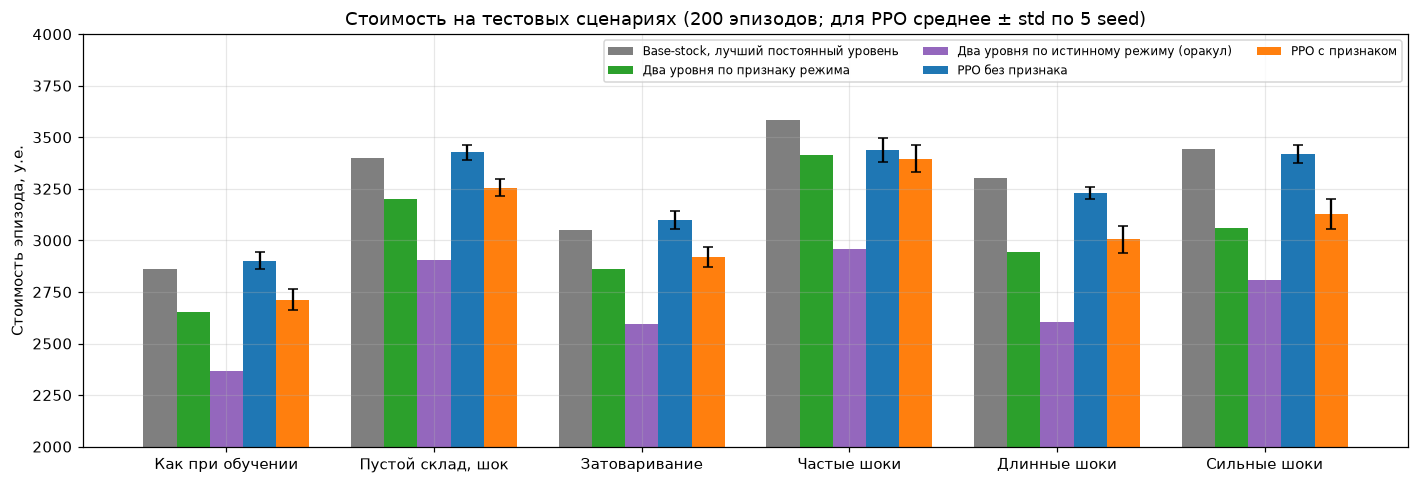

In [7]:
fig, ax = plt.subplots(figsize=(13, 4.5))
shown = ["base_stock_static", "base_stock_signal", "oracle", "base", "regime"]
width = 0.16
for i, name in enumerate(shown):
    g = test[test.policy == name].groupby("scenario").cost
    mean, std = g.mean()[scenarios], g.std()[scenarios].fillna(0)
    x = np.arange(len(scenarios)) + (i - 2) * width
    yerr = std if name in ("base", "regime") else None  # у эвристик один прогон, разброса по seed нет
    ax.bar(x, mean, width, yerr=yerr, capsize=3, color=COLORS[name], label=POLICY_LABELS[name])
ax.set_xticks(np.arange(len(scenarios)), [SCENARIO_LABELS[s] for s in scenarios])
ax.set(ylabel="Стоимость эпизода, у.е.", ylim=(2000, 4000),
       title="Стоимость на тестовых сценариях (200 эпизодов; для PPO среднее ± std по 5 seed)")
ax.legend(fontsize=8, ncol=3)
plt.tight_layout()
plt.show()

- Оба агента PPO на всех сценариях намного лучше случайной политики и base-stock, настроенного по
  спокойному режиму: обучение дало рабочие политики.
- PPO без признака по стоимости почти совпадает с лучшим постоянным уровнем (2902 против 2864 на основном
  сценарии, на 1,3 % хуже) — фактически он выучил постоянный уровень.
- PPO с признаком дешевле базового агента на 6,5 % (−190 у.е., 95 % ДИ [−257; −122], p = 0,0002) и дешевле
  лучшего постоянного уровня на 5,3 %. Простая эвристика с тем же признаком всё же лучше (2652): из её
  выигрыша над постоянным уровнем (212 у.е.) агент получает около 72 % (152 у.е.).
- Эвристика с признаком дешевле постоянного уровня на 7,4 %, оракул — на 17,4 %. Разница между ними — цена
  задержки распознавания: режим виден только по уже случившемуся спросу.
- Преимущество агента с признаком сохраняется при других начальных состояниях (пустой склад в шоке −5,0 %,
  затоваривание −5,8 %), при длинных (−6,9 %) и сильных (−8,6 %) шоках. Эти разницы проходят и поправку
  Бонферрони на 6 сравнений (p < 0,0083). При частых шоках разница −1,3 % незначима (p = 0,30).
- Опасение из п. 4 гипотезы про сильные шоки не подтвердилось: преимущество там наибольшее. Фильтр с
  заниженным σ шока всё равно относит большие отклонения спроса к шоку — в спокойном режиме они ещё менее
  вероятны, — так что признак остаётся информативным.

Ниже проверка, почему разрыв пропадает при частых шоках.

In [8]:
# Лучший постоянный уровень для сценариев с другой динамикой спроса (те же 300 эпизодов, что для эвристик)
# и средние уровни агентов в этих сценариях.
rows = []
for sc in config.TEST_SCENARIOS[3:]:
    costs = {s: summarize(rollout(BaseStockPolicy(s), config.TUNE_SEEDS, scenario=sc))["cost"] for s in range(36, 56)}
    pos = test[test.scenario == sc.name].groupby("policy")[["position_calm", "position_shock"]].mean()
    rows.append({"сценарий": SCENARIO_LABELS[sc.name], "лучший постоянный S": min(costs, key=costs.get)}
                | {f"{POLICY_LABELS[p]}: спок. / шок": f"{pos.loc[p, 'position_calm']:.1f} / {pos.loc[p, 'position_shock']:.1f}"
                   for p in ["base", "regime"]})
pd.DataFrame(rows).set_index("сценарий")

,лучший постоянный S,PPO без признака: спок. / шок,PPO с признаком: спок. / шок
сценарий,,,
Частые шоки,48,43.6 / 44.6,41.9 / 47.1
Длинные шоки,46,43.4 / 44.7,40.4 / 47.7
Сильные шоки,42,43.5 / 45.1,40.5 / 47.9


При доле шоков 55 % лучший постоянный уровень поднимается с 41 до 48, а оба агента держат меньше. Агент без
признака держит около 44 почти всё время и этим ближе к новому оптимуму, чем настроенный base-stock: на этом
сценарии он дешевле base-stock (3439 против 3584). Агент с признаком в коротких спокойных периодах (в
среднем около 8 шагов) опускает уровень до ~42 и при каждом новом шоке поднимает его заново с задержкой.
Вторая возможная причина — фильтр считает с обучающей вероятностью начала шока 0,04 вместо 0,12 и поэтому
медленнее признаёт шок. Эти причины здесь не разделены; для этого нужен прогон с фильтром, знающим
параметры сценария.

## 6. Как меняется управление запасом

Метрики на сценарии «как при обучении»: уровень (позиция после заказа) и запас отдельно по шоковым и
спокойным шагам, дефицит и составляющие стоимости.

In [9]:
mechanism_cols = {
    "position_calm": "уровень, спок.", "position_shock": "уровень, шок", "inv_calm": "запас, спок.", "inv_shock": "запас, шок",
    "stockout_calm": "дефицит, спок.", "stockout_shock": "дефицит, шок", "lost_share": "потерянный спрос",
    "holding": "хранение", "penalty": "штраф", "purchase": "закупка", "cost": "итого",
}
base_sc = test[test.scenario == "base"]
mechanism = (base_sc[base_sc.policy.isin(order[1:])].groupby("policy")[list(mechanism_cols)].mean()
             .loc[order[1:]].rename(index=POLICY_LABELS, columns=mechanism_cols))
print("Средние по 200 эпизодам (для PPO — ещё и по 5 seed). Дефицит — доля шагов с потерянным спросом.")
mechanism.style.format("{:.1f}").format("{:.1%}", subset=["дефицит, спок.", "дефицит, шок", "потерянный спрос"])

Средние по 200 эпизодам (для PPO — ещё и по 5 seed). Дефицит — доля шагов с потерянным спросом.


,"уровень, спок.","уровень, шок","запас, спок.","запас, шок","дефицит, спок.","дефицит, шок",потерянный спрос,хранение,штраф,закупка,итого
policy,,,,,,,,,,,
"Base-stock, уровень для спокойного режима",35.2,35.1,5.9,4.1,5.6%,41.8%,7.5%,540.1,1639.5,989.1,3168.7
"Base-stock, лучший постоянный уровень",41.1,41.0,11.3,6.9,0.6%,25.2%,3.8%,1001.2,827.1,1035.3,2863.6
Два уровня по признаку режима,38.8,47.0,9.7,10.1,1.6%,18.3%,2.9%,981.4,624.9,1045.3,2651.6
Два уровня по истинному режиму (оракул),36.3,51.0,7.8,11.8,2.5%,12.4%,1.9%,896.7,412.9,1055.1,2364.7
PPO без признака,43.5,44.6,13.7,9.2,0.4%,18.4%,2.8%,1235.6,617.6,1048.3,2901.6
PPO с признаком,40.3,47.0,11.1,10.3,0.9%,17.4%,2.7%,1083.2,580.3,1048.5,2712.0


In [10]:
for metric in ["position_shock", "position_calm", "stockout_shock", "stockout_calm", "holding", "penalty"]:
    row = compare(metric).loc[SCENARIO_LABELS["base"]]
    print(f"{mechanism_cols[metric]:>16}: без признака {row[POLICY_LABELS['base']]:.3f}, "
          f"с признаком {row[POLICY_LABELS['regime']]:.3f}, p = {row['p (Уэлч)']:.4f}")

    уровень, шок: без признака 44.563, с признаком 46.964, p = 0.0460
  уровень, спок.: без признака 43.460, с признаком 40.335, p = 0.0032
    дефицит, шок: без признака 0.184, с признаком 0.174, p = 0.3973
  дефицит, спок.: без признака 0.004, с признаком 0.009, p = 0.1278
        хранение: без признака 1235.604, с признаком 1083.152, p = 0.0219
           штраф: без признака 617.620, с признаком 580.320, p = 0.4088


- **Различение режимов.** У агента с признаком средний уровень 40,3 в спокойные и 47,0 в шоковые шаги
  (разница 6,6), у базового — 43,5 и 44,6 (разница 1,1). Различия между агентами значимы (p = 0,003 для
  спокойных шагов и p = 0,046 для шоковых). Пункт 1 гипотезы подтверждён.
- **Дефицит в шок почти не изменился:** 17,4 % шагов против 18,4 % (p = 0,40). Пункт 2 не подтверждён.
- **Откуда выигрыш.** Из 190 у.е. разницы 152 приходятся на хранение (1236 → 1083, p = 0,022) и только 37 —
  на штраф за дефицит (p = 0,41), закупка одинаковая (1048). Агент с признаком экономит в основном за счёт
  меньшего запаса в спокойные периоды, а не за счёт защиты от шока.
- Базовый агент почти не допускает дефицита в спокойные шаги (0,4 %): он держит страховой запас «на случай
  шока» всё время, это и есть его плата за то, что он не различает режимы.

## 7. Поведение агентов

Прогоны агентов на тестовых эпизодах сценария «как при обучении» для графиков ниже.

In [11]:
models = {(name, seed): PPO.load(f"models/{name}_s{seed}", device="cpu") for name in ["base", "regime"]
          for seed in config.MAIN["seeds"]}
traces = {key: rollout(SB3Policy(model), config.TEST_SEEDS, **config.CONDITIONS[key[0]])
          for key, model in models.items()}
heuristic_traces = {name: rollout(policy, config.TEST_SEEDS) for name, policy in HEURISTICS.items()}
episode_signal = []
for seed in config.TEST_SEEDS:
    env.reset(seed=seed)
    episode_signal.append(shock_signal(env))
episode_signal = np.array(episode_signal)
test_regime = heuristic_traces["oracle"]["regime"]

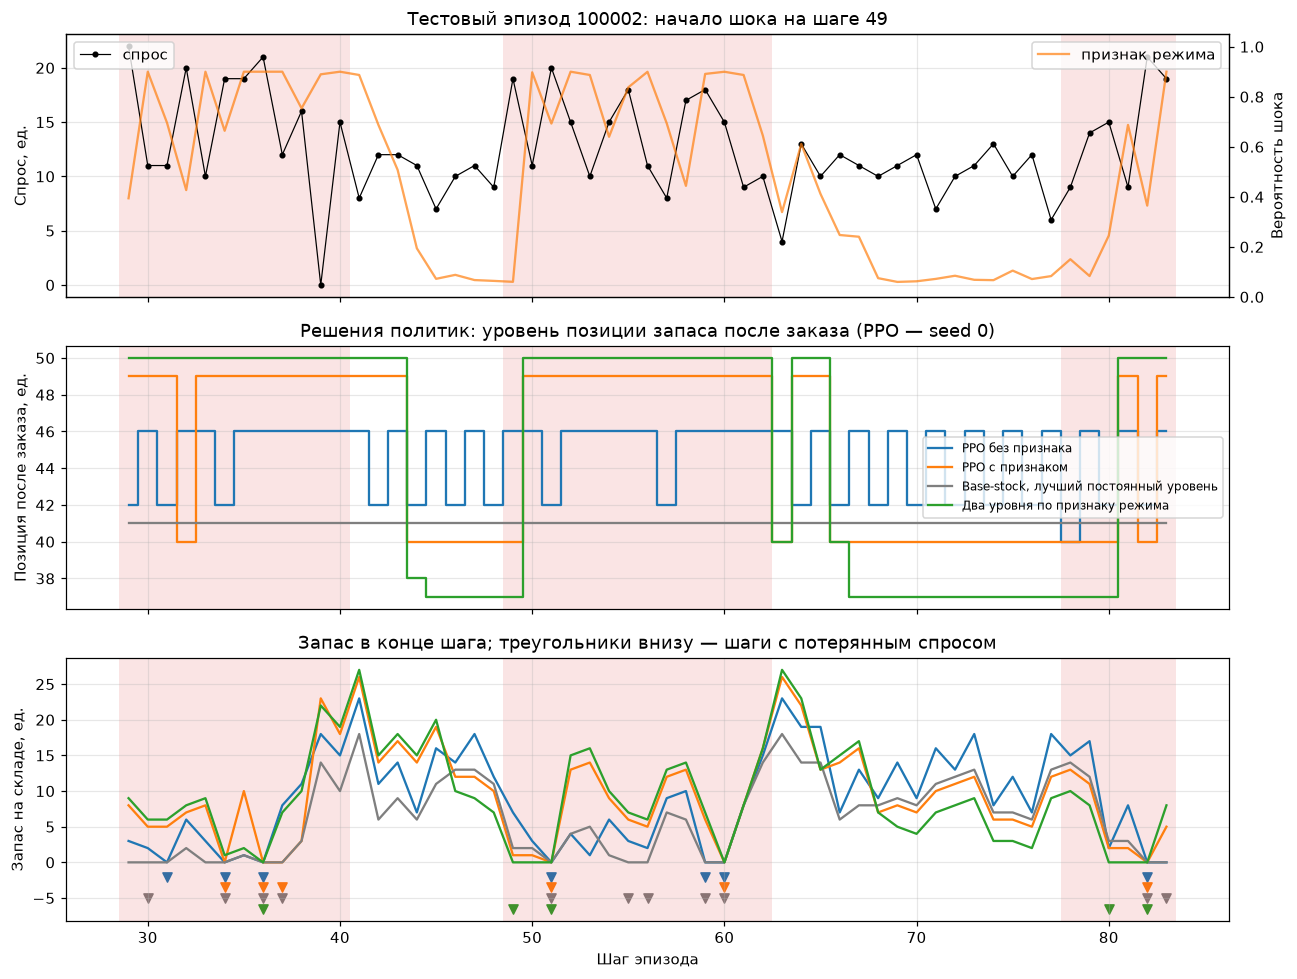

In [12]:
# Эпизод, в котором шок начинается в середине и длится не меньше 10 шагов
onsets = [(ep, t) for ep, t in zip(*np.nonzero((test_regime[:, 1:] == SHOCK) & (test_regime[:, :-1] != SHOCK)))
          if 30 <= t + 1 <= 60 and np.all(test_regime[ep, t + 1:t + 11] == SHOCK)]
ep, onset = onsets[0][0], onsets[0][1] + 1
window = np.arange(onset - 20, min(onset + 35, 100))

fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
tr0 = heuristic_traces["oracle"]
axes[0].plot(window, tr0["demand"][ep, window], "k.-", lw=0.8, label="спрос")
ax_sig = axes[0].twinx()
ax_sig.plot(window, episode_signal[ep, window], color="tab:orange", alpha=0.7, label="признак режима")
ax_sig.set(ylabel="Вероятность шока", ylim=(0, 1.05))
ax_sig.grid(False)
axes[0].set(ylabel="Спрос, ед.", title=f"Тестовый эпизод {config.TEST_SEEDS[ep]}: начало шока на шаге {onset}")
axes[0].legend(loc="upper left")
ax_sig.legend(loc="upper right")
for name, tr in [("base", traces[("base", 0)]), ("regime", traces[("regime", 0)]),
                 ("base_stock_static", heuristic_traces["base_stock_static"]),
                 ("base_stock_signal", heuristic_traces["base_stock_signal"])]:
    axes[1].step(window, tr["position"][ep, window], where="mid", color=COLORS[name], label=POLICY_LABELS[name])
    axes[2].plot(window, tr["inventory"][ep, window], color=COLORS[name], label=POLICY_LABELS[name])
    lost = window[tr["lost"][ep, window] > 0]
    axes[2].scatter(lost, np.full(len(lost), -2.0 - 1.5 * list(COLORS).index(name)), marker="v", color=COLORS[name])
axes[1].set(ylabel="Позиция после заказа, ед.", title="Решения политик: уровень позиции запаса после заказа (PPO — seed 0)")
axes[2].set(xlabel="Шаг эпизода", ylabel="Запас на складе, ед.",
            title="Запас в конце шага; треугольники внизу — шаги с потерянным спросом")
axes[1].legend(fontsize=8)
for ax in axes:
    shade_shocks(ax, test_regime[ep, window], t0=window[0])
plt.tight_layout()
plt.show()

Один эпизод может быть нетипичным, поэтому ниже то же усреднено по всем началам шока в 200 тестовых
эпизодах: средняя позиция после заказа и средний потерянный спрос в зависимости от времени относительно
первого шага шока.

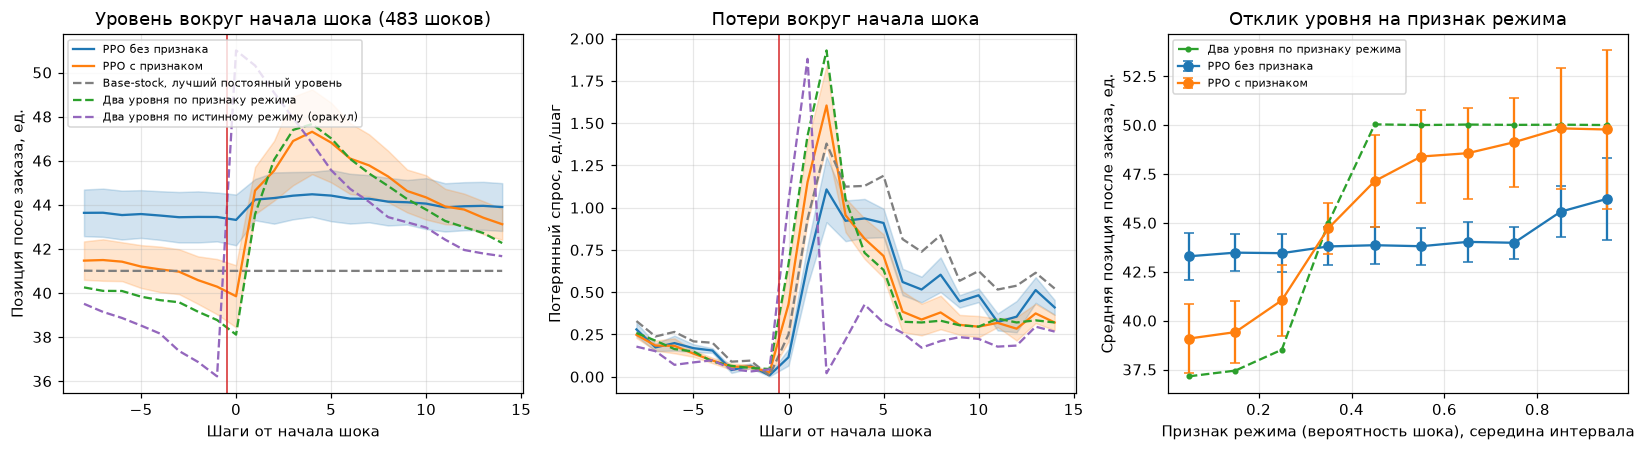

PPO: среднее по 5 seed ± std по seed; пунктир — эвристики. Красная линия — начало шока.
PPO без признака: потери на шаге +2 — 1.11 ед., в среднем на шагах +3…+10 — 0.67 ед./шаг
PPO с признаком: потери на шаге +2 — 1.60 ед., в среднем на шагах +3…+10 — 0.52 ед./шаг
Средняя позиция после заказа по интервалам признака:


,0.0–0.1,0.1–0.2,0.2–0.3,0.3–0.4,0.4–0.5,0.5–0.6,0.6–0.7,0.7–0.8,0.8–0.9,0.9–1.0
PPO без признака,43.3,43.5,43.4,43.8,43.9,43.8,44.0,44.0,45.6,46.2
PPO с признаком,39.1,39.4,41.0,44.7,47.1,48.4,48.6,49.1,49.8,49.8


In [13]:
def event_study(trace, metric, before=8, after=15):
    # Среднее значение метрики вокруг каждого перехода «спокойный -> шок» (сдвиг 0 = первый шаг шока).
    reg = trace["regime"]
    windows = [trace[metric][ep, t + 1 - before:t + 1 + after]
               for ep, t in zip(*np.nonzero((reg[:, 1:] == SHOCK) & (reg[:, :-1] != SHOCK)))
               if t + 1 - before >= 0 and t + 1 + after <= reg.shape[1]]
    return np.mean(windows, axis=0), len(windows)


lags = np.arange(-8, 15)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for name in ["base", "regime"]:
    for ax, metric in zip(axes, ["position", "lost"]):
        per_seed = np.array([event_study(traces[(name, s)], metric)[0] for s in config.MAIN["seeds"]])
        mean, std = per_seed.mean(0), per_seed.std(0, ddof=1)
        ax.plot(lags, mean, color=COLORS[name], label=POLICY_LABELS[name])
        ax.fill_between(lags, mean - std, mean + std, color=COLORS[name], alpha=0.2)
for name in ["base_stock_static", "base_stock_signal", "oracle"]:
    for ax, metric in zip(axes, ["position", "lost"]):
        ax.plot(lags, event_study(heuristic_traces[name], metric)[0], color=COLORS[name], ls="--",
                label=POLICY_LABELS[name])
n_events = event_study(heuristic_traces["oracle"], "position")[1]
axes[0].set(xlabel="Шаги от начала шока", ylabel="Позиция после заказа, ед.", title=f"Уровень вокруг начала шока ({n_events} шоков)")
axes[1].set(xlabel="Шаги от начала шока", ylabel="Потерянный спрос, ед./шаг", title="Потери вокруг начала шока")
for ax in axes[:2]:
    ax.axvline(-0.5, color="tab:red", lw=1)

# Отклик уровня на признак: средний S в зависимости от вероятности шока в посещённых состояниях
bins = np.linspace(0, 1, 11)
centers = (bins[:-1] + bins[1:]) / 2
idx = np.clip(np.digitize(episode_signal, bins) - 1, 0, len(centers) - 1)


def binned_position(trace):
    return [trace["position"][idx == b].mean() for b in range(len(centers))]


response = {}
for name in ["base", "regime"]:
    per_seed = np.array([binned_position(traces[(name, s)]) for s in config.MAIN["seeds"]])
    mean, std = per_seed.mean(0), per_seed.std(0, ddof=1)
    response[POLICY_LABELS[name]] = mean
    axes[2].errorbar(centers, mean, yerr=std, color=COLORS[name], marker="o", capsize=3, label=POLICY_LABELS[name])
axes[2].plot(centers, binned_position(heuristic_traces["base_stock_signal"]), color=COLORS["base_stock_signal"],
             ls="--", marker=".", label=POLICY_LABELS["base_stock_signal"])
axes[2].set(xlabel="Признак режима (вероятность шока), середина интервала", ylabel="Средняя позиция после заказа, ед.",
            title="Отклик уровня на признак режима")
axes[0].legend(fontsize=7, loc="upper left")
axes[2].legend(fontsize=7, loc="upper left")
plt.tight_layout()
plt.show()
print("PPO: среднее по 5 seed ± std по seed; пунктир — эвристики. Красная линия — начало шока.")
for name in ["base", "regime"]:
    lost = np.mean([event_study(traces[(name, s)], "lost")[0] for s in config.MAIN["seeds"]], axis=0)
    print(f"{POLICY_LABELS[name]}: потери на шаге +2 — {lost[lags == 2][0]:.2f} ед., "
          f"в среднем на шагах +3…+10 — {lost[(lags >= 3) & (lags <= 10)].mean():.2f} ед./шаг")
print("Средняя позиция после заказа по интервалам признака:")
pd.DataFrame(response, index=[f"{a:.1f}–{b:.1f}" for a, b in zip(bins[:-1], bins[1:])]).T.round(1)

- **Эпизод.** Агент с признаком ведёт себя почти как эвристика с двумя уровнями: около 49 в шок и 40 в
  спокойный период, переключается через 1–2 шага после смены режима. Базовый агент колеблется между 42 и 46
  в ответ на последний спрос, но режим не выделяет.
- **Начало шока (усреднение по 483 шокам).** До шока агент с признаком держит уровень ниже базового, после
  начала поднимает его к 3–4-му шагу примерно так же, как эвристика; оракул поднимает сразу. Потери у всех
  политик без знания режима максимальны на 2-м шаге шока: шок распознаётся только после первого высокого
  спроса, а заказ приходит ещё через 2 шага. На этом пике агент с признаком теряет больше базового (1,60
  против 1,11 ед.), потому что вошёл в шок с меньшим запасом, а на шагах +3…+10 — меньше (0,52 против
  0,67 ед./шаг). Эти эффекты почти компенсируют друг друга, поэтому доля дефицита в шок у агентов близка.
- **Отклик на признак.** У агента с признаком уровень монотонно растёт с вероятностью шока: 39,1 в интервале
  0–0,1 и 49,8 в интервале 0,9–1,0 — сглаженный вариант порога эвристики. У базового агента уровень почти не
  зависит от вероятности шока (43,3–44,0 до 0,8), хотя она считается из тех же 4 значений спроса, что он
  видит. Заметно (до 46,2) он растёт только при самых высоких значениях, когда последние значения спроса
  резко выше обычного.

## 8. Больший бюджет: 1,5M шагов

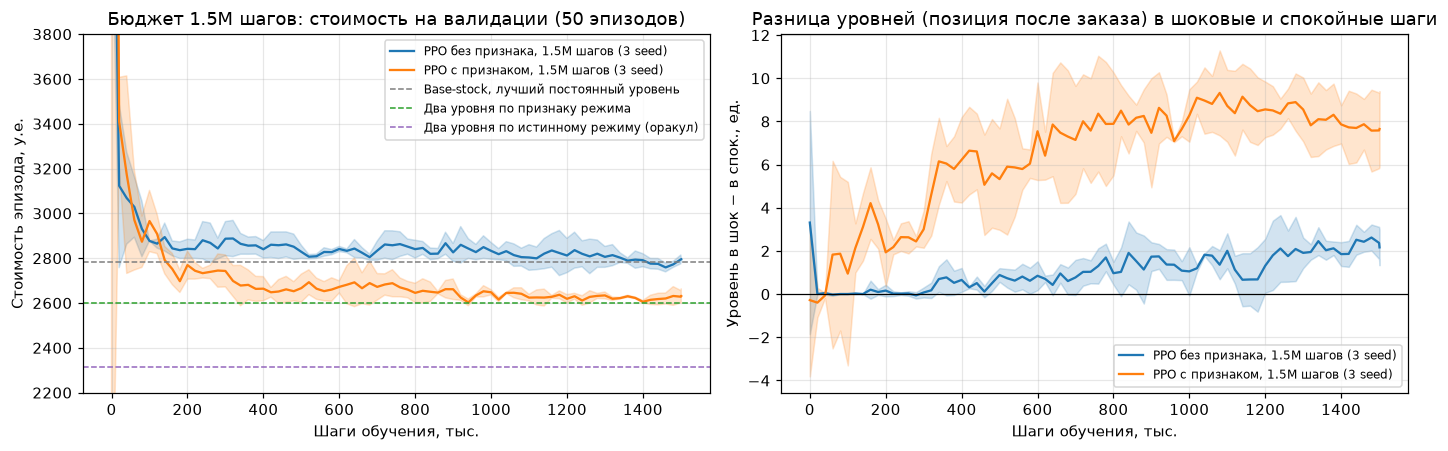

Средняя стоимость эпизода на тесте, у.е. (500k — 5 seed, 1.5M — 3 seed; среднее ± std по seed)


scenario,Как при обучении,"Пустой склад, шок",Затоваривание,Частые шоки,Длинные шоки,Сильные шоки
policy,,,,,,
PPO без признака,2902 ± 40,3426 ± 37,3099 ± 43,3439 ± 57,3228 ± 30,3419 ± 43
"PPO без признака, 1.5M шагов",2881 ± 7,3410 ± 15,3073 ± 6,3529 ± 85,3244 ± 52,3379 ± 67
PPO с признаком,2712 ± 51,3255 ± 42,2919 ± 47,3395 ± 66,3005 ± 65,3126 ± 72
"PPO с признаком, 1.5M шагов",2694 ± 42,3236 ± 41,2902 ± 37,3446 ± 83,2996 ± 60,3094 ± 48


In [14]:
plot_curves(["base_long", "regime_long"], "Бюджет 1.5M шагов")
long_order = ["base", "base_long", "regime", "regime_long"]
print("Средняя стоимость эпизода на тесте, у.е. (500k — 5 seed, 1.5M — 3 seed; среднее ± std по seed)")
mean_std_table("cost", long_order)

In [15]:
print("Уровень (позиция после заказа) по режимам на сценарии «как при обучении», среднее по seed:")
long_positions = base_sc.groupby("policy")[["position_calm", "position_shock"]].mean().loc[long_order]
long_positions["разница"] = long_positions["position_shock"] - long_positions["position_calm"]
long_positions.rename(index=POLICY_LABELS).round(1)

Уровень (позиция после заказа) по режимам на сценарии «как при обучении», среднее по seed:


,position_calm,position_shock,разница
policy,,,
PPO без признака,43.5,44.6,1.1
"PPO без признака, 1.5M шагов",42.0,44.2,2.2
PPO с признаком,40.3,47.0,6.6
"PPO с признаком, 1.5M шагов",39.5,47.1,7.5


In [16]:
long_comparison = compare("cost", a="regime_long", b="base_long")
long_comparison.style.format({POLICY_LABELS["base_long"]: "{:.0f}", POLICY_LABELS["regime_long"]: "{:.0f}",
                              "разница": "{:+.0f}", "разница, %": "{:+.1f}", "p (Уэлч)": "{:.4f}"})

,"PPO без признака, 1.5M шагов","PPO с признаком, 1.5M шагов",разница,"разница, %",95% ДИ,p (Уэлч)
сценарий,,,,,,
Как при обучении,2881,2694,-187,-6.5,[-287; -86],0.0144
"Пустой склад, шок",3410,3236,-173,-5.1,[-263; -84],0.0107
Затоваривание,3073,2902,-171,-5.6,[-259; -83],0.0132
Частые шоки,3529,3446,-83,-2.3,[-274; 109],0.2968
Длинные шоки,3244,2996,-248,-7.6,[-375; -120],0.0059
Сильные шоки,3379,3094,-286,-8.5,[-423; -148],0.0052


При бюджете 1,5M шагов разрыв не сократился: −187 у.е. (−6,5 %, 95 % ДИ [−287; −86], p = 0,014, 3 seed на
условие). Базовый агент стал стабильнее (std по seed 7 против 40) и чуть дешевле (2881 против 2902), начал
слабо различать режимы (разница уровней 2,2 против 1,1), но по стоимости остался на уровне постоянного
base-stock. Агент с признаком тоже немного улучшился (2694 против 2712). Дополнительное предсказание
(«разрыв сократится, но не исчезнет») подтвердилось только во второй части: за втрое больший бюджет базовый
агент не выучил режим из сырого спроса. По кривой разница уровней у него медленно растёт, так что при
гораздо большем бюджете он, возможно, догонит.

## 9. Выводы

**Итог по гипотезе H1.**

| пункт | ожидание | результат |
|---|---|---|
| 1 | агент с признаком различает режимы | да: разница уровней 6,6 против 1,1 |
| 2 | меньше дефицита в шоковые шаги | нет: 17,4 % против 18,4 %, p = 0,40 |
| 3 | стоимость ниже на 3–8 %, p < 0,05 | да: −6,5 %, p = 0,0002 |
| 4 | преимущество при частых, длинных и сильных шоках | при длинных и сильных — да, при частых — нет |

По решающему правилу H1 подтверждена **частично**: направление всех трёх основных эффектов верное, но
пункт 2 незначим. Признак режима снижает стоимость и меняет политику, но механизм другой, чем ожидалось:
агент экономит на запасе в спокойные периоды, а не защищается от дефицита в шок.

**Почему так.**
- У базового агента есть вся нужная информация, но выделить режим из 4 значений спроса — нелинейная задача
  (сравнить разброс с двумя дисперсиями), а польза от этого видна в награде только через 2–3 шага и тонет в
  случайности спроса. Постоянный уровень находится проще, и PPO сходится к нему. Готовый признак превращает
  задачу в почти линейную: «чем выше вероятность шока, тем выше уровень».
- Начало шока не защищает ни признак, ни сырой спрос: режим виден после первого высокого спроса, а заказ
  приходит через 2 шага. Поэтому знание режима окупается в основном в спокойные периоды (можно держать
  меньше) и в середине шока.

**Альтернативные объяснения.**
- *У агента с признаком больше информации.* Исключено построением: признак — функция наблюдения; в пилоте
  фильтр по всей истории давал то же, что по 4 значениям.
- *Дополнительный вход просто облегчает оптимизацию, а режим ни при чём.* Против этого — уровень агента
  монотонно зависит от признака и повторяет эвристику, а выигрыш приходится на спокойные шаги, где признак
  низкий. Прямой проверки «плацебо»-признаком с тем же распределением, но без связи со спросом, не было.
- *Гиперпараметры.* Подбирались по базовому агенту, так что если и смещают результат, то против гипотезы.
  Но подбор узкий (3 варианта); другая архитектура (например, рекуррентная сеть по длинной истории спроса)
  могла бы выделить режим сама.
- *Удача seed.* 5 seed на условие; доверительный интервал разницы не содержит 0 на 5 сценариях из 6, и
  результат повторился при бюджете 1,5M.

**Ограничения.**
- Упрощённая среда: один товар, нормальный спрос, два известных режима, постоянный срок поставки, нет
  фиксированной стоимости заказа.
- Фильтр использует истинные параметры обучающего процесса. На практике их надо оценивать (например, EM),
  ошибка параметров проверена только косвенно, через сценарии с другой динамикой.
- Один алгоритм (PPO), одна архитектура (MLP 64×64), узкий подбор гиперпараметров.
- 5 seed (3 при 1,5M) — мало для точной оценки разброса, доверительные интервалы широкие.
- Стоимости (h = 1, p = 20, c = 1) выбраны мной; при другом соотношении p/h ценность знания режима будет
  другой.
- Агент с признаком хуже простой эвристики с тем же признаком. В такой задаче на практике разумнее
  эвристика; RL имеет смысл там, где эвристику построить сложно (несколько товаров, ограничения склада).

**Когда результат должен переноситься на новые сценарии.** Когда (а) режимы отличаются прежде всего
разбросом спроса и держатся заметно дольше срока поставки (здесь шок в среднем 10 шагов при сроке 2);
(б) признак считается моделью, близкой к реальной структуре спроса (ошибка в σ шока не помешала, а
неверная частота шоков совпала с потерей преимущества); (в) дефицит дорог относительно хранения, так что
страховой запас существенен. Если шоки короткие по сравнению со сроком поставки или такие частые, что почти
всегда выгоден высокий постоянный уровень, признак мало что даст.

**Что проверить дальше.** Плацебо-признак; фильтр с параметрами, оценёнными по данным, и с верными
параметрами сценария «частые шоки»; рекуррентную политику на сырой истории спроса; другой алгоритм (DQN);
другие соотношения стоимостей и сроки поставки; бюджет больше 1,5M для базового агента.

## 10. Воспроизводимость

In [17]:
import platform

import gymnasium
import stable_baselines3

print("Python", platform.python_version(), "| torch", torch.__version__, "| stable-baselines3", stable_baselines3.__version__,
      "| gymnasium", gymnasium.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)
final = curves.sort_values("timesteps").groupby(["policy", "seed"]).tail(1)
budget = final.groupby("policy").agg(runs=("seed", "size"), minutes_per_run=("elapsed_s", lambda s: s.mean() / 60),
                                     total_minutes=("elapsed_s", lambda s: s.sum() / 60))
print("Время обучения (1 поток CPU на запуск, включая оценку для кривых):")
budget.round(1)

Python 3.11.18 | torch 2.15.0 | stable-baselines3 2.9.2 | gymnasium 1.4.0 | numpy 2.4.6 | pandas 3.1.1
Время обучения (1 поток CPU на запуск, включая оценку для кривых):


,runs,minutes_per_run,total_minutes
policy,,,
base,5,5.9,29.5
base_long,3,13.8,41.4
regime,5,6.6,33.1
regime_long,3,12.1,36.3


Время в таблице измерено на Apple M1 (8 ядер), когда машина была сильно загружена другими задачами (load
average 25–60), поэтому оно завышено. Первый прогон того же кода при меньшей загрузке занимал 2,6–3,8 мин на
запуск 500k и 7,8–9,3 мин на запуск 1,5M; кривые и тестовые метрики двух прогонов совпали полностью
(обучение детерминировано при фиксированных seed и одном потоке). Подбор эвристик — около 14 мин
процессорного времени, оценка — около 1,5 мин, выполнение ноутбука — около 1 мин. Всего около 100 мин
процессорного времени одного ядра M1. На Colab CPU (2 ядра, `--jobs 2`) это ориентировочно 1–2 часа; на
Colab я не запускал.

Команды (подробнее — в README):

```bash
pip install -r requirements.txt
python train.py --jobs 4          # 2 условия x 5 seed x 500k шагов
python train.py --long --jobs 3   # 2 условия x 3 seed x 1.5M шагов
python tune_baselines.py          # уровни эвристик -> results/baselines.json
python evaluate.py                # тест -> results/test_metrics.csv
jupyter nbconvert --to notebook --execute --inplace report.ipynb
```

Seed: обучение 0–4 (основной эксперимент) и 0–2 (1,5M шагов), обучающие среды получают seed
1000·k … 1000·k + 7; валидация 50000–50049; подбор эвристик 60000–60299; тест 100000–100199. Полный список
пакетов — `requirements-freeze.txt`.